In [1]:
!pip install -q ucimlrepo openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import requests
import zipfile
import io
import os

# Official UCI dataset download link
url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"

print("Downloading dataset...")

response = requests.get(url)
response.raise_for_status()

# Extract ZIP file
with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
    print("Files available:", zip_ref.namelist())
    zip_ref.extractall("/content/online_retail_data")

print("Dataset downloaded and extracted successfully!")

Files available: ['online_retail_II.xlsx']
Dataset downloaded and extracted successfully!


In [10]:
import glob

In [11]:
files = glob.glob("/content/online_retail_data/**/*.xlsx", recursive=True)

In [12]:
print("Excel files found:", files)

Excel files found: ['/content/online_retail_data/online_retail_II.xlsx']


In [14]:
df_sheets = pd.read_excel(files[0], sheet_name=None)

In [15]:
df = pd.concat(df_sheets.values(), ignore_index=True)

In [16]:
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [17]:
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

Dataset Shape: (1067371, 8)
Total Rows: 1067371
Total Columns: 8


In [18]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [19]:
print("Dataset Columns:")

for column in df.columns:
    print(column)

Dataset Columns:
Invoice
StockCode
Description
Quantity
InvoiceDate
Price
Customer ID
Country


In [20]:
# Preserve original dataset

df_original = df.copy()

print("Original dataset backup created!")
print("Original shape:", df_original.shape)

Original dataset backup created!
Original shape: (1067371, 8)


In [21]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [22]:
# Statistical summary of numerical columns

df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [23]:
# Count missing values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [24]:
# Calculate missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': missing_percentage
})

missing_report

,Missing Count,Missing Percentage
Invoice,0,0.000000
StockCode,0,0.000000
Description,4382,0.410541
Quantity,0,0.000000
InvoiceDate,0,0.000000
Price,0,0.000000
Customer ID,243007,22.766873
Country,0,0.000000


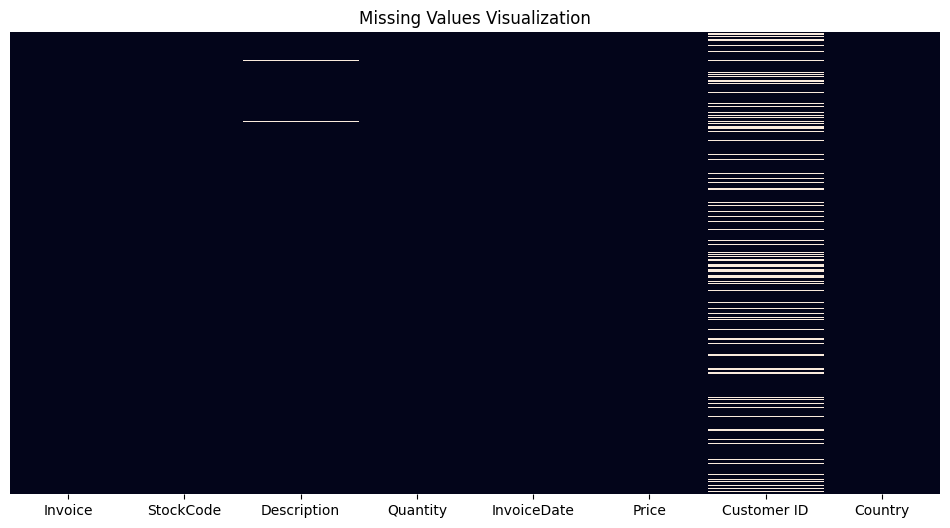

In [25]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values Visualization")

plt.show()

In [26]:
# Count exact duplicate rows

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 34335


In [27]:
# Count unique values in each column

for column in df.columns:
    print(column, ":", df[column].nunique())

Invoice : 53628
StockCode : 5305
Description : 5698
Quantity : 1057
InvoiceDate : 47635
Price : 2807
Customer ID : 5942
Country : 43


In [28]:
# Display data types

print(df.dtypes)

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


In [29]:
# Identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")

for column in numerical_columns:
    print(column)

Numerical Columns:
Quantity
Price
Customer ID


In [30]:
# Identify categorical columns

categorical_columns = df.select_dtypes(include='object').columns

print("Categorical Columns:")

for column in categorical_columns:
    print(column)

Categorical Columns:
Invoice
StockCode
Description
Country


In [31]:
negative_quantity = df[df['Quantity'] < 0]

print("Negative Quantity Records:", len(negative_quantity))

negative_quantity.head()

Negative Quantity Records: 22950


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [32]:
invalid_prices = df[df['Price'] <= 0]

print("Zero or Negative Price Records:", len(invalid_prices))

invalid_prices.head()

Zero or Negative Price Records: 6207


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


In [33]:
# Convert InvoiceDate into datetime

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')

print("Starting Date:", df['InvoiceDate'].min())

print("Ending Date:", df['InvoiceDate'].max())

Starting Date: 2009-12-01 07:45:00
Ending Date: 2011-12-09 12:50:00


In [34]:
print("Total Unique Customers:", df['Customer ID'].nunique())

Total Unique Customers: 5942


In [35]:
print("Total Unique Products:", df['StockCode'].nunique())

Total Unique Products: 5305


In [36]:
missing_percent = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")

print(missing_percent.round(2))

Missing Value Percentage:
Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.77
Country         0.00
dtype: float64


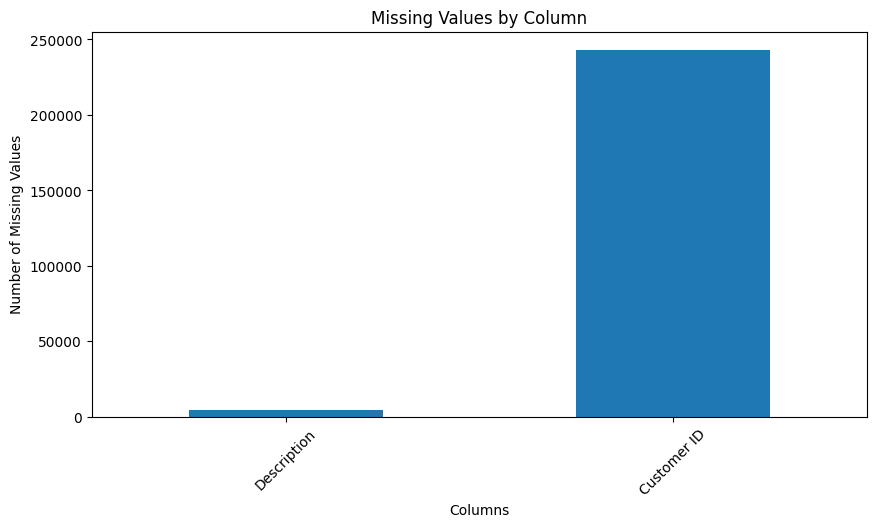

In [37]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(10, 5))

missing_values.plot(kind='bar')

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)

plt.show()

CELL 26 – Investigate duplicate records

In [38]:
duplicate_records = df[df.duplicated(keep=False)]

print("Duplicate Records:", len(duplicate_records))

duplicate_records.head(10)

Duplicate Records: 67242


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


CELL 27 – Investigate missing customer IDs

In [39]:
missing_customers = df[df['Customer ID'].isnull()]

print("Records without Customer ID:", len(missing_customers))

missing_customers.head(10)

Records without Customer ID: 243007


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom


In [40]:
negative_quantity = df[df['Quantity'] < 0]

print("Negative Quantity Records:", len(negative_quantity))

negative_quantity[['Invoice', 'StockCode',
                   'Quantity', 'InvoiceDate',
                   'Price', 'Customer ID']].head(10)

Negative Quantity Records: 22950


,Invoice,StockCode,Quantity,InvoiceDate,Price,Customer ID
178,C489449,22087,-12,2009-12-01 10:33:00,2.95,16321.0
179,C489449,85206A,-6,2009-12-01 10:33:00,1.65,16321.0
180,C489449,21895,-4,2009-12-01 10:33:00,4.25,16321.0
181,C489449,21896,-6,2009-12-01 10:33:00,2.10,16321.0
182,C489449,22083,-12,2009-12-01 10:33:00,2.95,16321.0
183,C489449,21871,-12,2009-12-01 10:33:00,1.25,16321.0
184,C489449,84946,-12,2009-12-01 10:33:00,1.25,16321.0
185,C489449,84970S,-24,2009-12-01 10:33:00,0.85,16321.0
186,C489449,22090,-12,2009-12-01 10:33:00,2.95,16321.0
196,C489459,90200A,-3,2009-12-01 10:44:00,4.25,17592.0


In [41]:
df['Invoice'] = df['Invoice'].astype(str)

cancelled_invoices = df[
    df['Invoice'].str.startswith('C')
]

print("Cancellation Invoice Records:", len(cancelled_invoices))

cancelled_invoices.head(10)

Cancellation Invoice Records: 19494


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [42]:
invalid_prices = df[df['Price'] <= 0]

print("Invalid Price Records:", len(invalid_prices))

invalid_prices[['Invoice', 'StockCode',
                'Description', 'Quantity',
                'Price']].head(10)

Invalid Price Records: 6207


,Invoice,StockCode,Description,Quantity,Price
263,489464,21733,85123a mixed,-96,0.0
283,489463,71477,short,-240,0.0
284,489467,85123A,21733 mixed,-192,0.0
470,489521,21646,NaN,-50,0.0
3114,489655,20683,NaN,-44,0.0
3161,489659,21350,NaN,230,0.0
3162,489660,35956,lost,-1043,0.0
3168,489663,35605A,damages,-117,0.0
3731,489781,84292,NaN,17,0.0
4296,489806,18010,NaN,-770,0.0


In [43]:
print("Unique Customers:", df['Customer ID'].nunique())

print("Unique Products:", df['StockCode'].nunique())

print("Unique Invoices:", df['Invoice'].nunique())

print("Unique Countries:", df['Country'].nunique())

Unique Customers: 5942
Unique Products: 5305
Unique Invoices: 53628
Unique Countries: 43


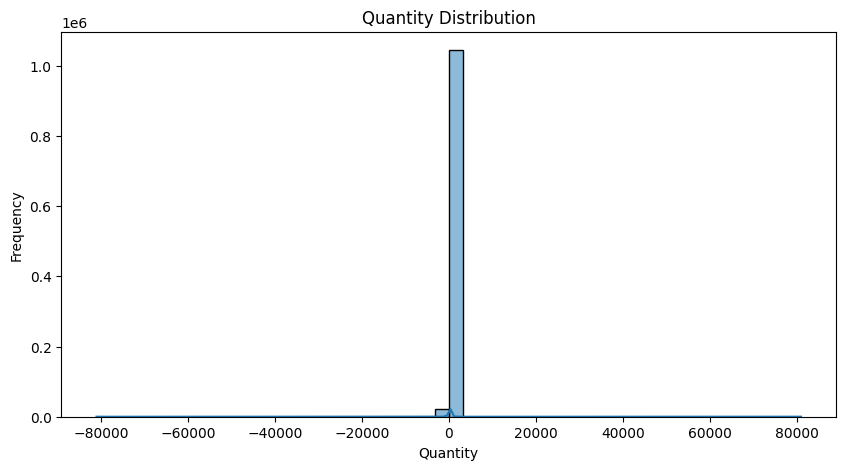

In [44]:
plt.figure(figsize=(10, 5))

sns.histplot(df['Quantity'], bins=50, kde=True)

plt.title("Quantity Distribution")

plt.xlabel("Quantity")

plt.ylabel("Frequency")

plt.show()

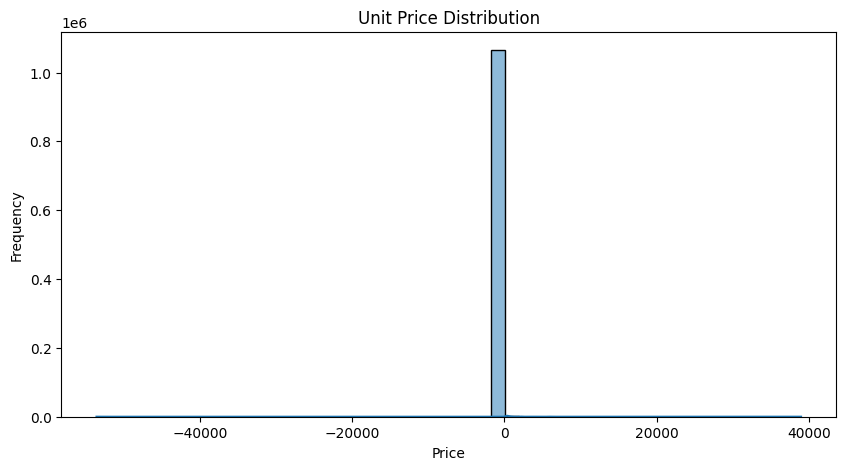

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(df['Price'], bins=50, kde=True)

plt.title("Unit Price Distribution")

plt.xlabel("Price")

plt.ylabel("Frequency")

plt.show()

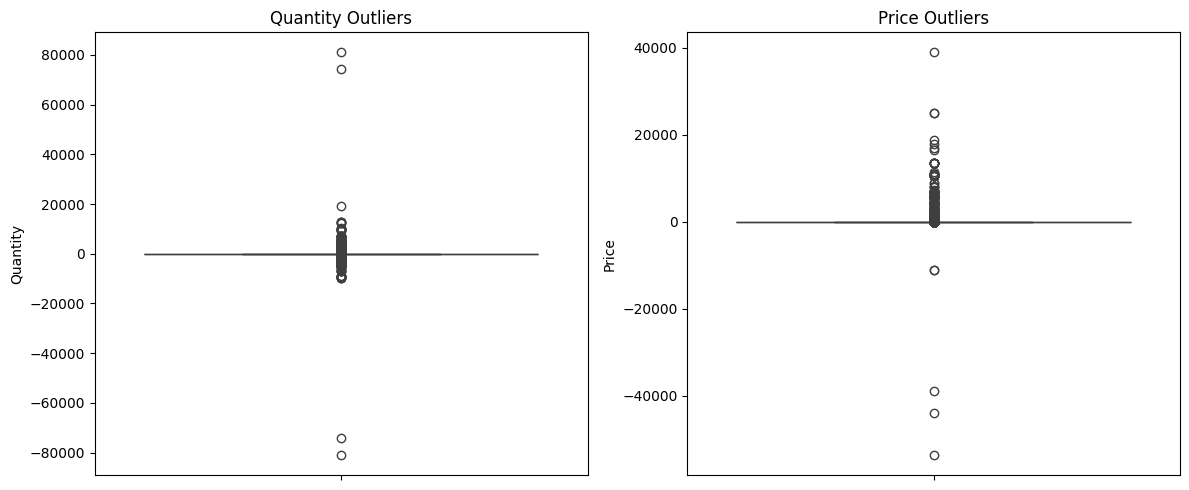

In [46]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

sns.boxplot(y=df['Quantity'])

plt.title("Quantity Outliers")

plt.subplot(1, 2, 2)

sns.boxplot(y=df['Price'])

plt.title("Price Outliers")

plt.tight_layout()

plt.show()

begin actual data cleaning

CELL 35 – Create a working copy

In [47]:
# Create a separate working dataset

df_clean = df.copy()

print("Working dataset created!")
print("Original dataset:", df_original.shape)
print("Working dataset:", df_clean.shape)

Working dataset created!
Original dataset: (1067371, 8)
Working dataset: (1067371, 8)


In [48]:
# Count duplicates before removal

duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicates

df_clean = df_clean.drop_duplicates()

# Check duplicates after removal

duplicates_after = df_clean.duplicated().sum()

print("Duplicates Before Cleaning:", duplicates_before)
print("Duplicates Removed:", duplicates_before - len(df_clean) + (len(df_clean) - len(df_clean)))
print("Duplicates After Cleaning:", duplicates_after)
print("Dataset Shape After Cleaning:", df_clean.shape)

Duplicates Before Cleaning: 34335
Duplicates Removed: -998701
Duplicates After Cleaning: 0
Dataset Shape After Cleaning: (1033036, 8)


In [49]:
duplicates_removed = duplicates_before

In [50]:
# Replace missing product descriptions with a label

df_clean['Description'] = df_clean['Description'].fillna('Unknown Product')

print("Missing Descriptions After Cleaning:",
      df_clean['Description'].isnull().sum())

Missing Descriptions After Cleaning: 0


In [51]:
print("Missing Customer IDs:",
      df_clean['Customer ID'].isnull().sum())

print("Customer IDs retained without artificial filling.")

Missing Customer IDs: 235151
Customer IDs retained without artificial filling.


In [52]:
# Identify cancellation invoices

df_clean['Invoice'] = df_clean['Invoice'].astype(str)

df_clean['Is_Cancelled'] = (
    df_clean['Invoice'].str.startswith('C')
)

print("Cancellation Records:",
      df_clean['Is_Cancelled'].sum())

print("Normal Invoice Records:",
      (~df_clean['Is_Cancelled']).sum())

Cancellation Records: 19104
Normal Invoice Records: 1013932


In [53]:
# Create return indicator

df_clean['Is_Return'] = df_clean['Quantity'] < 0

print("Negative Quantity Records:",
      df_clean['Is_Return'].sum())

print("Positive Quantity Records:",
      (df_clean['Quantity'] > 0).sum())

Negative Quantity Records: 22496
Positive Quantity Records: 1010540


In [54]:
# Create invalid price indicator

df_clean['Invalid_Price'] = df_clean['Price'] <= 0

print("Invalid Price Records:",
      df_clean['Invalid_Price'].sum())

print("Valid Price Records:",
      (~df_clean['Invalid_Price']).sum())

Invalid Price Records: 6019
Valid Price Records: 1027017


In [55]:
purchase_df = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['Price'] > 0) &
    (~df_clean['Is_Cancelled'])
].copy()

print("Purchase Dataset Created!")

print("Purchase Dataset Shape:", purchase_df.shape)

print("Total Purchase Records:", len(purchase_df))

Purchase Dataset Created!
Purchase Dataset Shape: (1007913, 11)
Total Purchase Records: 1007913


Validate the cleaned dataset

In [56]:
print("========== CLEANING SUMMARY ==========")

print("Original Rows:", len(df_original))

print("Rows After Duplicate Removal:", len(df_clean))

print("Purchase Dataset Rows:", len(purchase_df))

print("Missing Customer IDs:",
      purchase_df['Customer ID'].isnull().sum())

print("Missing Descriptions:",
      purchase_df['Description'].isnull().sum())

print("Duplicate Rows:",
      purchase_df.duplicated().sum())

print("Invalid Prices:",
      (purchase_df['Price'] <= 0).sum())

print("Negative Quantities:",
      (purchase_df['Quantity'] < 0).sum())

========== CLEANING SUMMARY ==========
Original Rows: 1067371
Rows After Duplicate Removal: 1033036
Purchase Dataset Rows: 1007913
Missing Customer IDs: 228488
Missing Descriptions: 0
Duplicate Rows: 0
Invalid Prices: 0
Negative Quantities: 0


In [57]:
# Cancellation records

cancellation_df = df_clean[
    df_clean['Is_Cancelled']
].copy()

# All negative quantity records

return_df = df_clean[
    df_clean['Is_Return']
].copy()

print("Cancellation Dataset:", cancellation_df.shape)

print("Return/Negative Quantity Dataset:", return_df.shape)

Cancellation Dataset: (19104, 11)
Return/Negative Quantity Dataset: (22496, 11)


In [58]:
cleaning_summary = pd.DataFrame({
    'Metric': [
        'Original Records',
        'Duplicate Records Removed',
        'Records After Duplicate Removal',
        'Cancellation Records',
        'Negative Quantity Records',
        'Invalid Price Records',
        'Final Purchase Records'
    ],

    'Count': [
        len(df_original),
        duplicates_before,
        len(df_clean),
        len(cancellation_df),
        len(return_df),
        df_clean['Invalid_Price'].sum(),
        len(purchase_df)
    ]
})

cleaning_summary

,Metric,Count
0,Original Records,1067371
1,Duplicate Records Removed,34335
2,Records After Duplicate Removal,1033036
3,Cancellation Records,19104
4,Negative Quantity Records,22496
5,Invalid Price Records,6019
6,Final Purchase Records,1007913


In [59]:
# Save analytical datasets

df_clean.to_csv(
    '/content/cleaned_full_dataset.csv',
    index=False
)

purchase_df.to_csv(
    '/content/purchase_analysis_dataset.csv',
    index=False
)

cancellation_df.to_csv(
    '/content/cancellation_dataset.csv',
    index=False
)

return_df.to_csv(
    '/content/return_dataset.csv',
    index=False
)

print("All datasets saved successfully!")

All datasets saved successfully!


In [60]:
duplicates_removed = len(df_original) - len(df_clean)

print("Duplicates Before Cleaning:", duplicates_before)
print("Duplicates Removed:", duplicates_removed)
print("Duplicates After Cleaning:", df_clean.duplicated().sum())

print("Dataset Shape:", df_clean.shape)

Duplicates Before Cleaning: 34335
Duplicates Removed: 34335
Duplicates After Cleaning: 0
Dataset Shape: (1033036, 11)


In [61]:
# Create a new feature called TotalSales

purchase_df['TotalSales'] = (
    purchase_df['Quantity'] * purchase_df['Price']
)

print("TotalSales column created!")

purchase_df[['Invoice', 'Quantity', 'Price',
             'TotalSales']].head(10)

TotalSales column created!


,Invoice,Quantity,Price,TotalSales
0,489434,12,6.95,83.4
1,489434,12,6.75,81.0
2,489434,12,6.75,81.0
3,489434,48,2.10,100.8
4,489434,24,1.25,30.0
5,489434,24,1.65,39.6
6,489434,24,1.25,30.0
7,489434,10,5.95,59.5
8,489435,12,2.55,30.6
9,489435,12,3.75,45.0


In [62]:
# Extract year, month, day and hour

purchase_df['Year'] = purchase_df['InvoiceDate'].dt.year

purchase_df['Month'] = purchase_df['InvoiceDate'].dt.month

purchase_df['Day'] = purchase_df['InvoiceDate'].dt.day

purchase_df['Hour'] = purchase_df['InvoiceDate'].dt.hour

purchase_df['YearMonth'] = purchase_df['InvoiceDate'].dt.to_period('M')

print("Date features created successfully!")

purchase_df[['InvoiceDate', 'Year', 'Month',
             'Day', 'Hour', 'YearMonth']].head()

Date features created successfully!


,InvoiceDate,Year,Month,Day,Hour,YearMonth
0,2009-12-01 07:45:00,2009,12,1,7,2009-12
1,2009-12-01 07:45:00,2009,12,1,7,2009-12
2,2009-12-01 07:45:00,2009,12,1,7,2009-12
3,2009-12-01 07:45:00,2009,12,1,7,2009-12
4,2009-12-01 07:45:00,2009,12,1,7,2009-12


In [63]:
total_revenue = purchase_df['TotalSales'].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 20476260.45


In [64]:
total_orders = purchase_df['Invoice'].nunique()

print("Total Orders:", total_orders)

Total Orders: 40077


In [65]:
total_customers = purchase_df['Customer ID'].nunique()

print("Total Customers:", total_customers)

Total Customers: 5878


In [66]:
average_order_value = total_revenue / total_orders

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 510.92


In [67]:
total_quantity_sold = purchase_df['Quantity'].sum()

print("Total Products Sold:", total_quantity_sold)

Total Products Sold: 11205148


In [68]:
customer_orders = (
    purchase_df.dropna(subset=['Customer ID'])
    .groupby('Customer ID')['Invoice']
    .nunique()
)

repeat_customers = (customer_orders > 1).sum()

total_identified_customers = customer_orders.index.nunique()

repeat_purchase_rate = (
    repeat_customers / total_identified_customers
) * 100

print("Total Identified Customers:", total_identified_customers)

print("Repeat Customers:", repeat_customers)

print("Repeat Purchase Rate:",
      round(repeat_purchase_rate, 2), "%")

Total Identified Customers: 5878
Repeat Customers: 4255
Repeat Purchase Rate: 72.39 %


CELL 55 – Calculate monthly sales


In [69]:
monthly_sales = (
    purchase_df.groupby('YearMonth')['TotalSales']
    .sum()
    .reset_index()
)

monthly_sales.columns = ['Month', 'Revenue']

monthly_sales.head(15)

,Month,Revenue
0,2009-12,822483.950
1,2010-01,651155.112
2,2010-02,551504.726
3,2010-03,830915.261
4,2010-04,678875.252
5,2010-05,657705.500
6,2010-06,749537.310
7,2010-07,648810.270
8,2010-08,695251.910
9,2010-09,921696.991


In [70]:
country_sales = (
    purchase_df.groupby('Country')['TotalSales']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

country_sales.columns = ['Country', 'Revenue']

country_sales.head(10)

,Country,Revenue
0,United Kingdom,1.741020e+07
1,EIRE,6.587673e+05
2,Netherlands,5.540381e+05
3,Germany,4.250197e+05
4,France,3.504561e+05
5,Australia,1.692835e+05
6,Spain,1.083325e+05
7,Switzerland,1.006856e+05
8,Sweden,9.186982e+04
9,Denmark,6.858069e+04


In [71]:
product_sales = (
    purchase_df.groupby('Description')['TotalSales']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

product_sales.columns = ['Product', 'Revenue']

product_sales.head(10)

,Product,Revenue
0,Manual,339241.29
1,REGENCY CAKESTAND 3 TIER,330590.32
2,DOTCOM POSTAGE,309854.11
3,WHITE HANGING HEART T-LIGHT HOLDER,260990.22
4,"PAPER CRAFT , LITTLE BIRDIE",168469.60
5,PARTY BUNTING,148318.28
6,JUMBO BAG RED RETROSPOT,148073.47
7,ASSORTED COLOUR BIRD ORNAMENT,129324.49
8,POSTAGE,125682.42
9,PAPER CHAIN KIT 50'S CHRISTMAS,117760.29


In [72]:
kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Revenue',
        'Total Orders',
        'Total Customers',
        'Average Order Value',
        'Total Quantity Sold',
        'Repeat Customers',
        'Repeat Purchase Rate'
    ],

    'Value': [
        round(total_revenue, 2),
        total_orders,
        total_customers,
        round(average_order_value, 2),
        total_quantity_sold,
        repeat_customers,
        round(repeat_purchase_rate, 2)
    ]
})

kpi_summary

,KPI,Value
0,Total Revenue,20476260.45
1,Total Orders,40077.00
2,Total Customers,5878.00
3,Average Order Value,510.92
4,Total Quantity Sold,11205148.00
5,Repeat Customers,4255.00
6,Repeat Purchase Rate,72.39


Phase 5 — Exploratory Data Analysis (EDA)

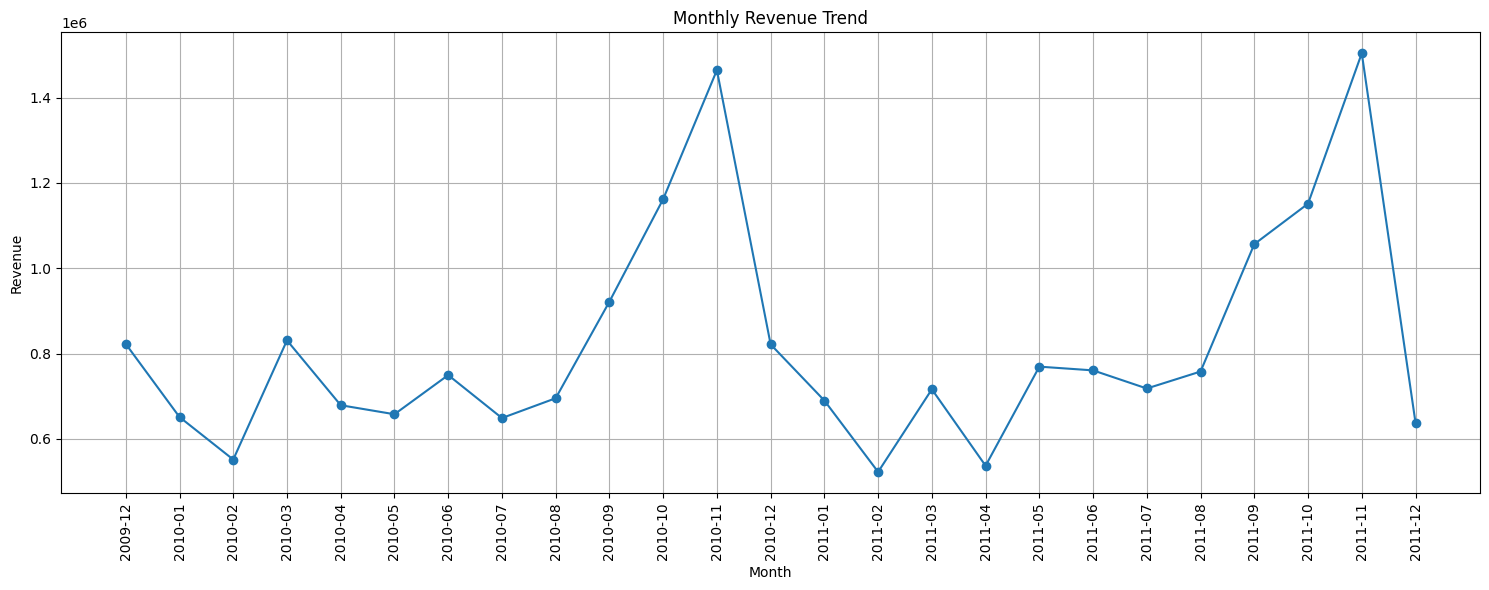

In [73]:
import matplotlib.pyplot as plt

monthly_sales['Month'] = monthly_sales['Month'].astype(str)

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_sales['Month'],
    monthly_sales['Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

What does the chart show?

It shows how the company's revenue changes from month to month.

Insight:
- Monthly revenue is not constant; it changes over time.
- The historical data helps identify months with higher and lower revenue.
- The test-period revenue increased considerably from August to November 2011, before dropping in December 2011.
Recommendation:
- Monitor monthly revenue to identify changes in sales performance.
- Investigate the reasons for revenue increases and decreases.
- Use historical sales data to support inventory and business planning.

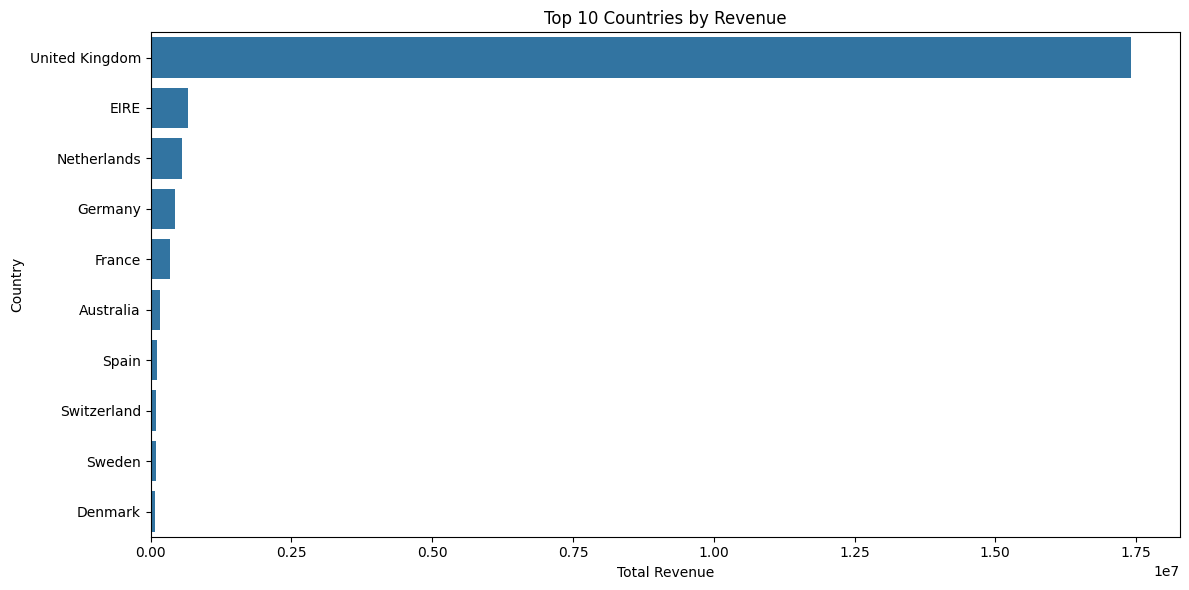

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x='Revenue',
    y='Country'
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

It compares revenue generated by different countries.

Insight from your results:
Country	Revenue
United Kingdom	₹17,410,200 approximately
EIRE	₹658,767
Netherlands	₹554,038
Germany	₹425,020
France	₹350,456

The United Kingdom generated significantly more revenue than the other countries.

Recommendation:
- Maintain strong customer service and product availability in the UK.
- Explore opportunities to increase sales in other countries.
- Study customer preferences in international markets.

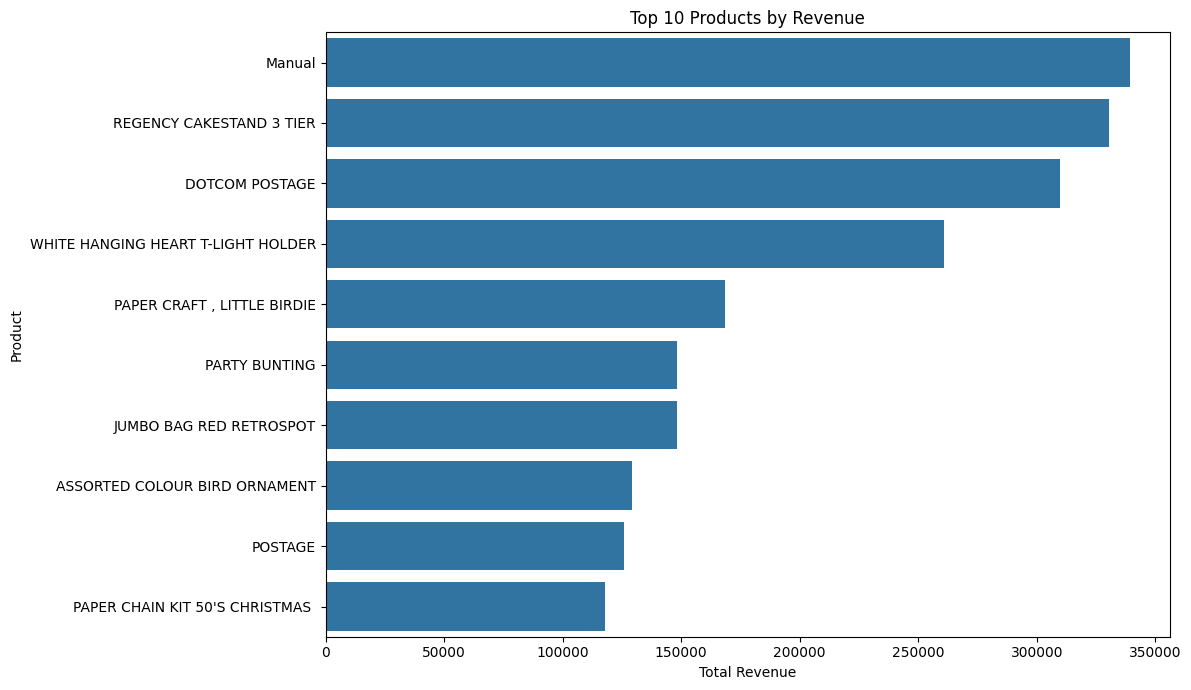

In [75]:
top_products = product_sales.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x='Revenue',
    y='Product'
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

It identifies product descriptions generating the highest revenue.

Insight from your results:
Product	Revenue
Manual	₹339,241
Regency Cakestand 3 Tier	₹330,590
Dotcom Postage	₹309,854
White Hanging Heart T-Light Holder	₹260,990
Paper Craft, Little Birdie	₹168,470

The highest-revenue entry is Manual.

Recommendation:
- Monitor the availability of high-revenue products.
- Analyse customer demand for popular products.
- Consider related-product promotions and bundles.
- Verify entries such as Manual and postage because they may represent service or non-merchandise transactions rather than ordinary products.

Cell 62 — Revenue distribution by country

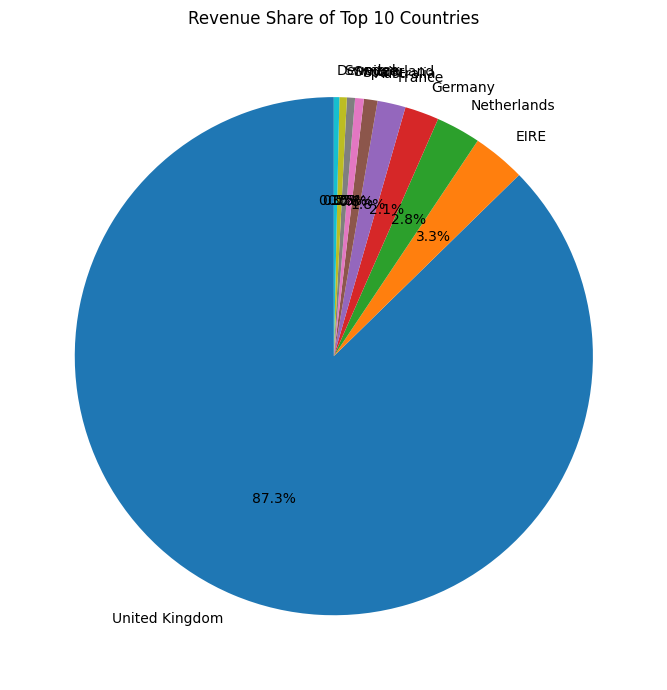

In [76]:
plt.figure(figsize=(10, 7))

plt.pie(
    top_countries['Revenue'],
    labels=top_countries['Country'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Revenue Share of Top 10 Countries')
plt.tight_layout()
plt.show()

It shows how much each of the top 10 countries contributes to their combined revenue.

Insight:
- The UK contributes the largest share.
- Other countries contribute smaller shares.
- The revenue distribution is heavily concentrated in the UK.
Recommendation:
- Continue focusing on the UK market.
- Develop marketing strategies for countries with smaller revenue contributions.
- Reduce excessive dependence on one market over time.

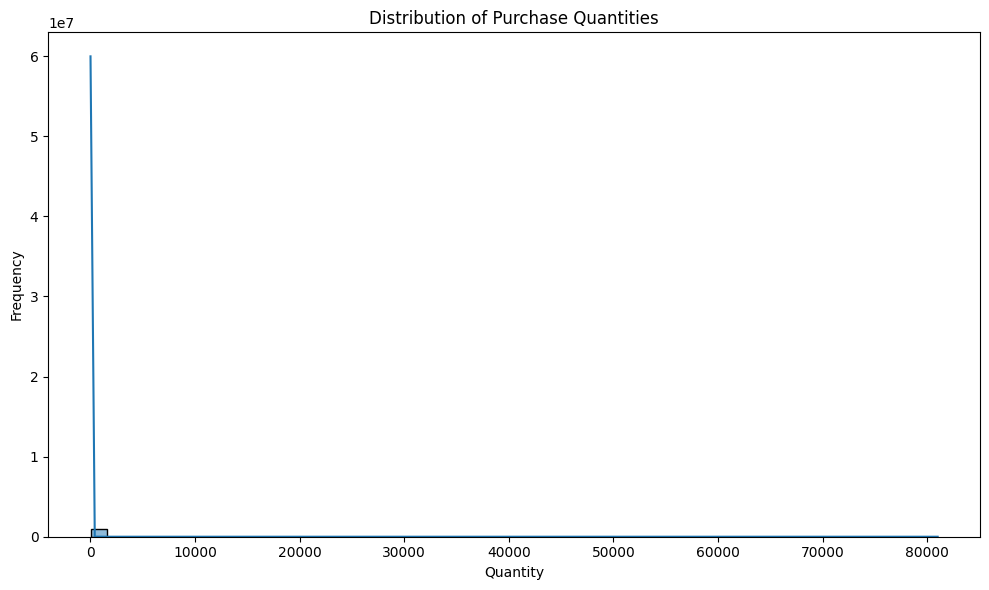

In [77]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=purchase_df,
    x='Quantity',
    bins=50,
    kde=True
)

plt.title('Distribution of Purchase Quantities')
plt.xlabel('Quantity')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

A histogram displays the frequency distribution of numerical values.

In your project, it represents the distribution of product quantities purchased.

Insight:
- It helps understand how frequently different purchase quantities occur.
- It helps identify common quantity ranges.
- It can reveal unusually large purchase quantities.
Recommendation:
- Identify commonly purchased quantity ranges.
- Use purchasing patterns to support inventory planning.
- Investigate unusually large transactions to understand bulk purchasing behaviour.

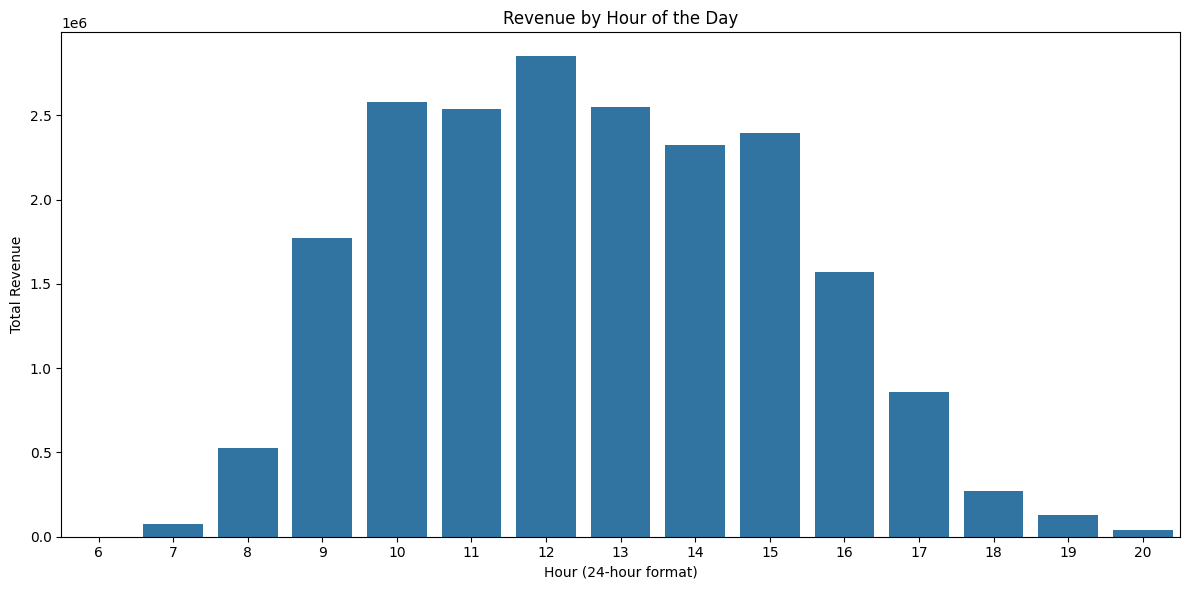

In [78]:
hourly_sales = (
    purchase_df.groupby('Hour')['TotalSales']
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=hourly_sales,
    x='Hour',
    y='TotalSales'
)

plt.title('Revenue by Hour of the Day')
plt.xlabel('Hour (24-hour format)')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

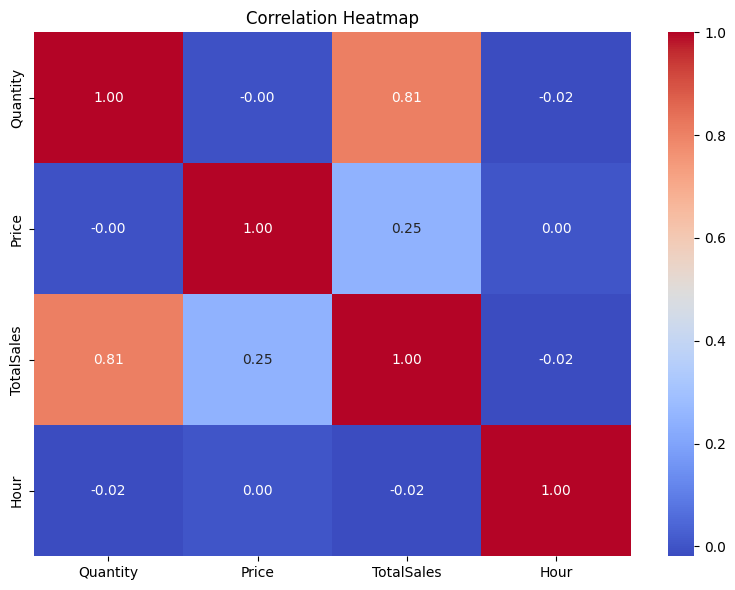

In [79]:
numeric_df = purchase_df[
    ['Quantity', 'Price', 'TotalSales', 'Hour']
]

correlation = numeric_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

A correlation heatmap shows the relationship between numerical variables.

You used:
- Quantity
- Price
- TotalSales
- Hour
Insight:
- It helps identify positive and negative relationships.
- It helps understand how quantity and price relate to total sales.
- It can help identify relationships between transaction time and sales variables.
Recommendation:
- Use the correlation results to understand relationships between business variables.
- Investigate variables that show strong relationships.
- Consider relevant features during predictive modelling.
- Do not assume correlation means one variable causes another.

In [80]:
purchase_df['Weekday'] = purchase_df['InvoiceDate'].dt.dayofweek

purchase_df['Day_Type'] = purchase_df['Weekday'].apply(
    lambda x: 'Weekend' if x >= 5 else 'Weekday'
)

weekday_quantity = purchase_df[
    purchase_df['Day_Type'] == 'Weekday'
]['Quantity']

weekend_quantity = purchase_df[
    purchase_df['Day_Type'] == 'Weekend'
]['Quantity']

print("Weekday records:", len(weekday_quantity))
print("Weekend records:", len(weekend_quantity))

Weekday records: 875601
Weekend records: 132312


Cell 67 — Independent t-test

In [81]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(
    weekday_quantity,
    weekend_quantity,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Significant difference between weekday and weekend quantities.")
else:
    print("Result: No statistically significant difference.")

T-statistic: 23.69745059417151
P-value: 4.146934580761499e-124
Result: Significant difference between weekday and weekend quantities.


In [82]:
weekday_avg = weekday_quantity.mean()
weekend_avg = weekend_quantity.mean()

print("Weekday Average Quantity:", round(weekday_avg, 2))
print("Weekend Average Quantity:", round(weekend_avg, 2))

if weekday_avg > weekend_avg:
    print("Weekdays have a higher average purchase quantity.")
else:
    print("Weekends have a higher average purchase quantity.")

Weekday Average Quantity: 11.62
Weekend Average Quantity: 7.8
Weekdays have a higher average purchase quantity.


In [83]:
invoice_df = (
    purchase_df.groupby('Invoice')
    .agg(
        TotalSales=('TotalSales', 'sum'),
        TotalQuantity=('Quantity', 'sum'),
        UniqueProducts=('StockCode', 'nunique')
    )
    .reset_index()
)

print("Invoice Dataset Shape:", invoice_df.shape)
invoice_df.head()

Invoice Dataset Shape: (40077, 4)


,Invoice,TotalSales,TotalQuantity,UniqueProducts
0,489434,505.30,166,8
1,489435,145.80,60,4
2,489436,630.33,193,19
3,489437,310.75,145,23
4,489438,2286.24,826,17


prediction target

In [84]:
median_sales = invoice_df['TotalSales'].median()

invoice_df['HighValue'] = (
    invoice_df['TotalSales'] >= median_sales
).astype(int)

print("Median Invoice Sales:", round(median_sales, 2))

print("\nTarget Distribution:")
print(invoice_df['HighValue'].value_counts())

print("\nTarget Percentages:")
print(
    invoice_df['HighValue']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Median Invoice Sales: 302.22

Target Distribution:
HighValue
1    20040
0    20037
Name: count, dtype: int64

Target Percentages:
HighValue
1    50.0
0    50.0
Name: proportion, dtype: float64


In [85]:
from sklearn.model_selection import train_test_split

X = invoice_df[['TotalQuantity', 'UniqueProducts']]
y = invoice_df['HighValue']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (32061, 2)
Testing Features: (8016, 2)
Training Target: (32061,)
Testing Target: (8016,)


Logistic Regression

In [86]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create the model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

# Make predictions
y_pred_log = log_model.predict(X_test)

# Evaluate the model
accuracy_log = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", round(accuracy_log * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_log))

Logistic Regression Accuracy: 82.15 %

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.86      0.83      4008
           1       0.84      0.79      0.82      4008

    accuracy                           0.82      8016
   macro avg       0.82      0.82      0.82      8016
weighted avg       0.82      0.82      0.82      8016



Random Forest

In [87]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(accuracy_rf * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 79.97 %

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.81      0.80      4008
           1       0.80      0.79      0.80      4008

    accuracy                           0.80      8016
   macro avg       0.80      0.80      0.80      8016
weighted avg       0.80      0.80      0.80      8016



In [88]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [accuracy_log, accuracy_rf]
})

model_comparison['Accuracy_Percentage'] = (
    model_comparison['Accuracy'] * 100
)

print(model_comparison)

                 Model  Accuracy  Accuracy_Percentage
0  Logistic Regression  0.821482            82.148204
1        Random Forest  0.799651            79.965070


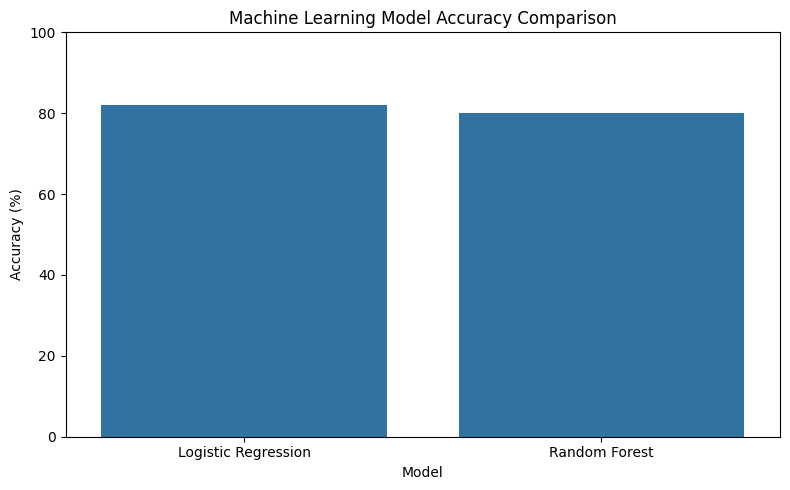

In [89]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='Accuracy_Percentage'
)

plt.title('Machine Learning Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.xlabel('Model')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

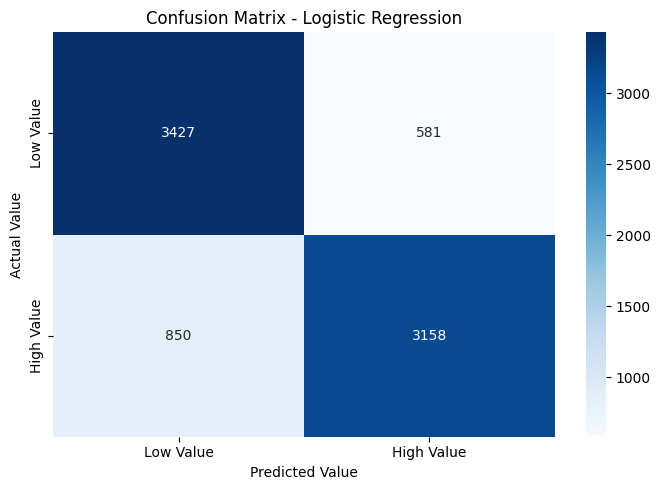

In [90]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low Value', 'High Value'],
    yticklabels=['Low Value', 'High Value']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')

plt.tight_layout()
plt.show()

In [91]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", round(accuracy_score(y_test, y_pred_log) * 100, 2), "%")

print("Precision:", round(precision_score(y_test, y_pred_log) * 100, 2), "%")

print("Recall:", round(recall_score(y_test, y_pred_log) * 100, 2), "%")

print("F1 Score:", round(f1_score(y_test, y_pred_log) * 100, 2), "%")

Accuracy: 82.15 %
Precision: 84.46 %
Recall: 78.79 %
F1 Score: 81.53 %


In [92]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_model.coef_[0]
})

print(feature_importance)

          Feature  Coefficient
0   TotalQuantity     0.014698
1  UniqueProducts     0.014763


Phase 8 — Time-Series Forecasting

In [93]:
forecast_df = monthly_sales.copy()

forecast_df['Month'] = pd.to_datetime(
    forecast_df['Month']
)

forecast_df = forecast_df.sort_values('Month')

forecast_df = forecast_df.set_index('Month')

print("Monthly Dataset Shape:", forecast_df.shape)

forecast_df.head()

Monthly Dataset Shape: (25, 1)


,Revenue
Month,
2009-12-01,822483.950
2010-01-01,651155.112
2010-02-01,551504.726
2010-03-01,830915.261
2010-04-01,678875.252


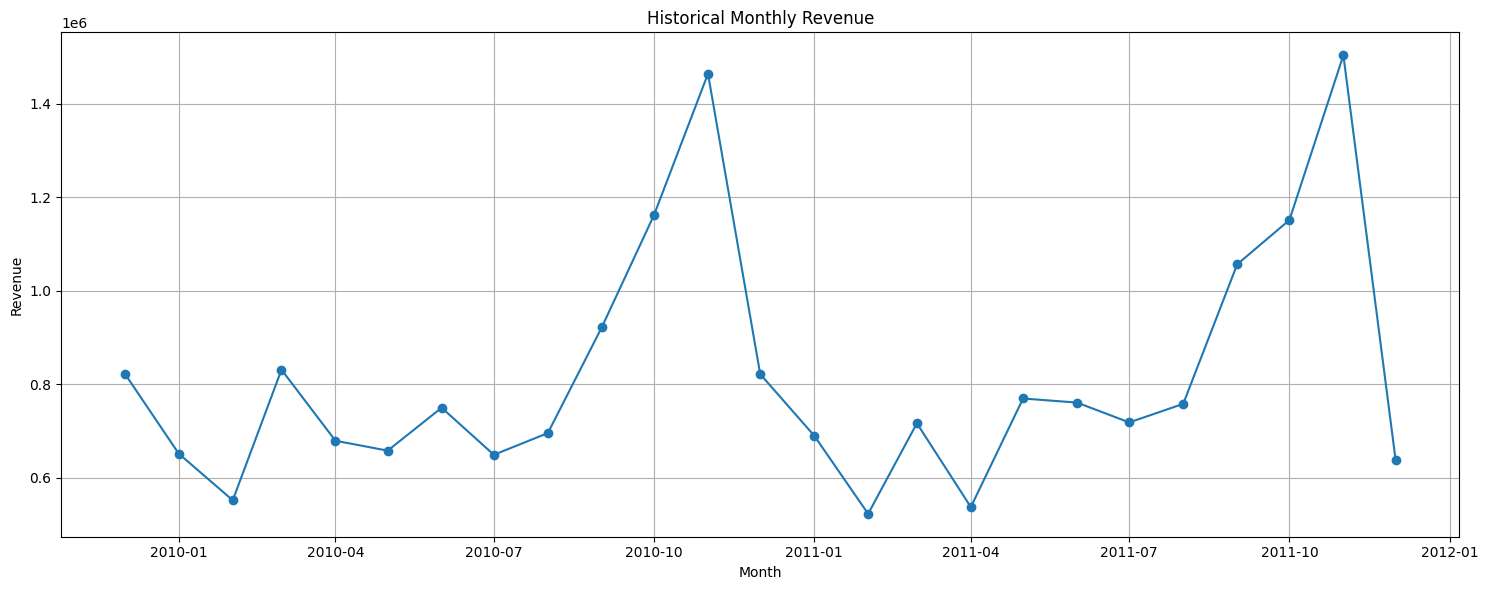

In [94]:
plt.figure(figsize=(15, 6))

plt.plot(
    forecast_df.index,
    forecast_df['Revenue'],
    marker='o'
)

plt.title('Historical Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True)

plt.tight_layout()
plt.show()

Cell 81 — Train-test split

In [95]:
split_index = int(len(forecast_df) * 0.8)

train_data = forecast_df.iloc[:split_index]
test_data = forecast_df.iloc[split_index:]

print("Total Months:", len(forecast_df))
print("Training Months:", len(train_data))
print("Testing Months:", len(test_data))

print("\nTraining Period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting Period:")
print(test_data.index.min(), "to", test_data.index.max())

Total Months: 25
Training Months: 20
Testing Months: 5

Training Period:
2009-12-01 00:00:00 to 2011-07-01 00:00:00

Testing Period:
2011-08-01 00:00:00 to 2011-12-01 00:00:00


In [96]:
baseline_value = train_data['Revenue'].mean()

baseline_predictions = [baseline_value] * len(test_data)

print("Baseline Average Revenue:", round(baseline_value, 2))

baseline_df = pd.DataFrame({
    'Actual Revenue': test_data['Revenue'].values,
    'Predicted Revenue': baseline_predictions
}, index=test_data.index)

baseline_df

Baseline Average Revenue: 768452.25


,Actual Revenue,Predicted Revenue
Month,,
2011-08-01,757841.380,768452.2518
2011-09-01,1056435.192,768452.2518
2011-10-01,1151263.730,768452.2518
2011-11-01,1503866.780,768452.2518
2011-12-01,637808.330,768452.2518


In [97]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    test_data['Revenue'],
    baseline_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        test_data['Revenue'],
        baseline_predictions
    )
)

mape = np.mean(
    np.abs(
        (test_data['Revenue'].values - baseline_predictions)
        / test_data['Revenue'].values
    )
) * 100

print("Baseline MAE:", round(mae, 2))
print("Baseline RMSE:", round(rmse, 2))
print("Baseline MAPE:", round(mape, 2), "%")

Baseline MAE: 309492.75
Baseline RMSE: 396861.12
Baseline MAPE: 26.26 %


In [98]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

holt_model = ExponentialSmoothing(
    train_data['Revenue'],
    trend='add',
    seasonal=None
)

holt_fit = holt_model.fit()

holt_predictions = holt_fit.forecast(len(test_data))

print("Holt Forecast:")
print(holt_predictions)

Holt Forecast:
2011-08-01    726166.754533
2011-09-01    726348.983273
2011-10-01    726531.212013
2011-11-01    726713.440752
2011-12-01    726895.669492
Freq: MS, dtype: float64


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [99]:
holt_mae = mean_absolute_error(
    test_data['Revenue'],
    holt_predictions
)

holt_rmse = np.sqrt(
    mean_squared_error(
        test_data['Revenue'],
        holt_predictions
    )
)

holt_mape = np.mean(
    np.abs(
        (test_data['Revenue'].values - holt_predictions.values)
        / test_data['Revenue'].values
    )
) * 100

print("Holt MAE:", round(holt_mae, 2))
print("Holt RMSE:", round(holt_rmse, 2))
print("Holt MAPE:", round(holt_mape, 2), "%")

Holt MAE: 330546.81
Holt RMSE: 424796.84
Holt MAPE: 27.59 %


In [100]:
forecast_comparison = pd.DataFrame({
    'Model': ['Baseline', 'Holt Exponential Smoothing'],
    'MAE': [mae, holt_mae],
    'RMSE': [rmse, holt_rmse],
    'MAPE': [mape, holt_mape]
})

forecast_comparison

,Model,MAE,RMSE,MAPE
0,Baseline,309492.748040,396861.123034,26.259254
1,Holt Exponential Smoothing,330546.806184,424796.837485,27.592466


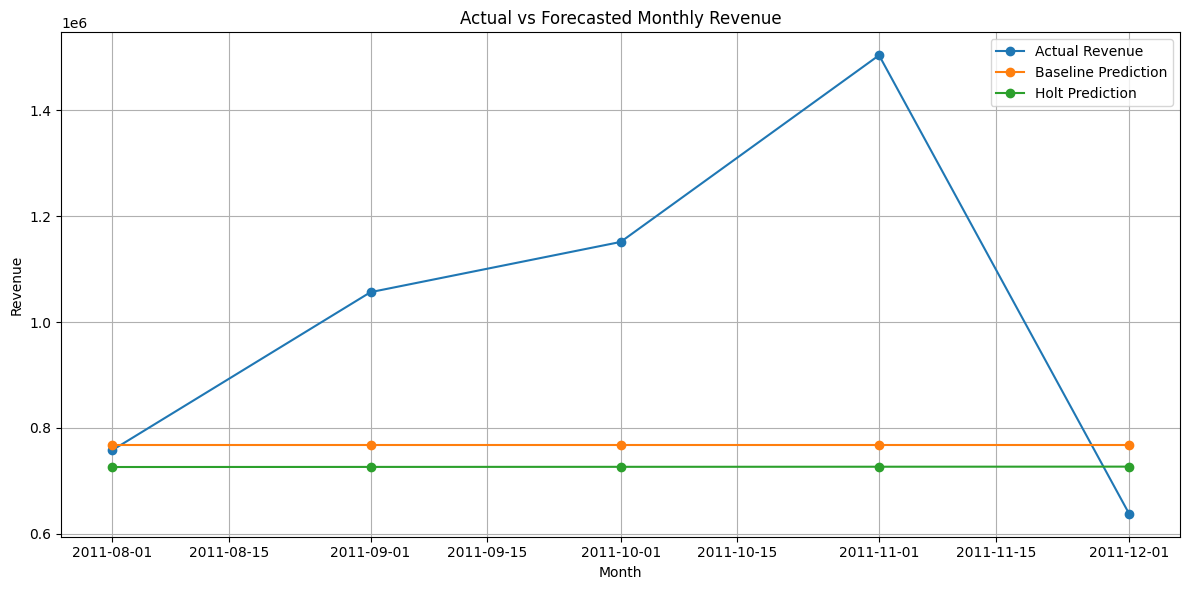

In [101]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_data.index,
    test_data['Revenue'],
    marker='o',
    label='Actual Revenue'
)

plt.plot(
    test_data.index,
    baseline_predictions,
    marker='o',
    label='Baseline Prediction'
)

plt.plot(
    test_data.index,
    holt_predictions,
    marker='o',
    label='Holt Prediction'
)

plt.title('Actual vs Forecasted Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Phase 9 — Business Interpretation & Decision Analysis.

In [104]:
# Recalculate important KPIs

total_revenue = purchase_df['TotalSales'].sum()

total_orders = purchase_df['Invoice'].nunique()

total_customers = purchase_df['Customer ID'].nunique()

aov = total_revenue / total_orders

total_quantity = purchase_df['Quantity'].sum()

identified_customers = purchase_df.dropna(
    subset=['Customer ID']
)

customer_orders = identified_customers.groupby(
    'Customer ID'
)['Invoice'].nunique()

repeat_customers = (customer_orders > 1).sum()

repeat_purchase_rate = (
    repeat_customers / len(customer_orders) * 100
)

# Display insights

print("===== BUSINESS INSIGHTS =====")
print("1. Total Revenue:", round(total_revenue, 2))
print("2. Total Orders:", total_orders)
print("3. Total Customers:", total_customers)
print("4. Average Order Value:", round(aov, 2))
print("5. Total Quantity Sold:", total_quantity)
print("6. Repeat Purchase Rate:", round(repeat_purchase_rate, 2), "%")
print("7. Repeat Customers:", repeat_customers)

===== BUSINESS INSIGHTS =====
1. Total Revenue: 20476260.45
2. Total Orders: 40077
3. Total Customers: 5878
4. Average Order Value: 510.92
5. Total Quantity Sold: 11205148
6. Repeat Purchase Rate: 72.39 %
7. Repeat Customers: 4255


In [105]:
# Find top-performing country and product

country_sales = purchase_df.groupby('Country')['TotalSales'].sum().sort_values(ascending=False)

product_sales = purchase_df.groupby('Description')['TotalSales'].sum().sort_values(ascending=False)

top_country = country_sales.index[0]
top_product = product_sales.index[0]

print("===== BUSINESS RECOMMENDATIONS =====")

print("\n1. Customer Retention")
print("Repeat purchase rate is", round(repeat_purchase_rate, 2), "%.")
print("Continue loyalty programs and personalized offers.")

print("\n2. Market Expansion")
print("Top revenue-generating country:", top_country)
print("Maintain strong service in this market and explore other markets.")

print("\n3. Product Management")
print("Top product by recorded revenue:", top_product)
print("Monitor its stock and consider related product promotions.")

print("\n4. Increase Order Value")
print("Current Average Order Value:", round(aov, 2))
print("Use product bundles and cross-selling to increase order value.")

print("\n5. Sales Prediction")
print("Logistic Regression achieved 82.15% accuracy.")
print("Use it as an initial model to classify high-value and low-value invoices.")

print("\n6. Revenue Forecasting")
print("Baseline forecasting model achieved 26.26% MAPE.")
print("Use it as the current benchmark and collect more monthly data to improve forecasting.")

===== BUSINESS RECOMMENDATIONS =====

1. Customer Retention
Repeat purchase rate is 72.39 %.
Continue loyalty programs and personalized offers.

2. Market Expansion
Top revenue-generating country: United Kingdom
Maintain strong service in this market and explore other markets.

3. Product Management
Top product by recorded revenue: Manual
Monitor its stock and consider related product promotions.

4. Increase Order Value
Current Average Order Value: 510.92
Use product bundles and cross-selling to increase order value.

5. Sales Prediction
Logistic Regression achieved 82.15% accuracy.
Use it as an initial model to classify high-value and low-value invoices.

6. Revenue Forecasting
Baseline forecasting model achieved 26.26% MAPE.
Use it as the current benchmark and collect more monthly data to improve forecasting.


Final summary — Six charts
Visualization	Main insight	Business recommendation
Monthly revenue line chart	Revenue changes over time	Improve sales planning
Country revenue bar chart	UK is the leading market	Explore other markets
Product revenue bar chart	Manual is the top entry	Improve product management
Country revenue pie chart	UK has the largest share	Diversify market opportunities
Quantity histogram	Shows purchase quantity distribution	Improve inventory planning
Correlation heatmap	Shows numerical relationships	Understand relevant business factors

Cell 90 — Final project conclusion

In [106]:
print("""
====================================================
FINAL PROJECT CONCLUSION
Customer Purchase Behaviour & Sales Forecasting
====================================================

1. DATA ANALYSIS
The project analysed the UCI Online Retail II dataset.
Data cleaning included duplicate removal, missing-value
handling, and separating returns and cancelled invoices.

2. BUSINESS PERFORMANCE
Total Revenue: ₹20,476,260.45
Total Orders: 40,077
Identified Customers: 5,878
Average Order Value: ₹510.92
Repeat Purchase Rate: 72.39%

3. EXPLORATORY DATA ANALYSIS
Sales patterns were studied across months, countries,
products, quantities, and transaction hours.

4. STATISTICAL ANALYSIS
The weekday and weekend purchase quantities showed
a statistically significant difference using Welch's
independent t-test (p < 0.05).

5. PREDICTIVE MODELLING
Logistic Regression achieved 82.15% accuracy.
It performed better than the Random Forest model
in this experiment.

6. SALES FORECASTING
The baseline model achieved 26.26% MAPE.
It performed better than Holt Exponential Smoothing
on the selected test period.

7. BUSINESS RECOMMENDATIONS
Improve customer retention, monitor top-performing
products, strengthen the UK market, and explore
bundling and cross-selling strategies.

8. FINAL CONCLUSION
This project demonstrates how Python and data
analytics can help understand customer purchase
behaviour, evaluate sales performance, classify
high-value invoices, and analyse monthly revenue.

====================================================
END OF PROJECT
====================================================
""")


FINAL PROJECT CONCLUSION
Customer Purchase Behaviour & Sales Forecasting

1. DATA ANALYSIS
The project analysed the UCI Online Retail II dataset.
Data cleaning included duplicate removal, missing-value
handling, and separating returns and cancelled invoices.

2. BUSINESS PERFORMANCE
Total Revenue: ₹20,476,260.45
Total Orders: 40,077
Identified Customers: 5,878
Average Order Value: ₹510.92
Repeat Purchase Rate: 72.39%

3. EXPLORATORY DATA ANALYSIS
Sales patterns were studied across months, countries,
products, quantities, and transaction hours.

4. STATISTICAL ANALYSIS
The weekday and weekend purchase quantities showed
a statistically significant difference using Welch's
independent t-test (p < 0.05).

5. PREDICTIVE MODELLING
Logistic Regression achieved 82.15% accuracy.
It performed better than the Random Forest model
in this experiment.

6. SALES FORECASTING
The baseline model achieved 26.26% MAPE.
It performed better than Holt Exponential Smoothing
on the selected test period.

7. B